<a href="https://colab.research.google.com/github/yerim410/AI/blob/main/Week10_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10주차 실습 — 강화학습으로 정책 개선: MDP·보상 · 사전학습 PPO 비교 · BC→RL 미세조정
**AI Application · 스마트모빌리티학과 · 2026-11-04**

| 셀 | 내용 |
|---|---|
| 0-1 | 이 머신의 속도 측정 → 예상 실행 시간, FAST 자동 설정 |
| 1 | MDP 와 보상 — 에피소드 보상을 항별로 분해 (전문가 vs 시작 정책, 외란 1.2×) |
| 2 | 사전학습 정책 비교 — 시작 정책 / ppo_scratch / ppo_bc12 / base_dr × 레벨 L1·L2·L4 |
| 3 | 단일 파일 PPO — 벡터 환경 · Agent(actor/critic 분리) · GAE · 클립 업데이트 · BC 정규화 |
| 4 | BC→RL 미세조정 실행 (1.6만 스텝, FAST 8천) — 곡선 |
| 5 | 짝지은 비교(시드 3) + ppo_best.onnx 저장 |
| 6 | (읽기) 보상 설계 — 항의 가중치가 '누가 좋은 정책인가'를 바꾼다 |

**준비물**: `tinytrack.py` (0.3.0), `models/ppo_scratch.onnx`·`ppo_bc12.onnx`·`ppo_report.json`·`base_pilotnet_dr.onnx`·`base_pilotnet.pt`, Drive 의 `week07/my_policy_v2.pt`(없으면 v1 → 즉석). CPU 로 전체 8~10분.

**약어**: RL = 강화학습 · MDP = Markov Decision Process(상태·행동·전이·보상·할인율) · PPO = Proximal Policy Optimization(Schulman 외 2017, arXiv:1707.06347) · GAE = Generalized Advantage Estimation(일반화 이득 추정) · BC = 행동 복제 · KL = 쿨백-라이블러 발산 · ONNX = 공통 모델 형식

In [1]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json, copy
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch, torch.nn as nn
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
assert tt.__version__ >= "0.3.0", "tinytrack 0.3.0 이상이 필요합니다 (e2e_starter 최신본)"
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week10"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

MODELS = Path("models") if Path("models/ppo_bc12.onnx").exists() else Path(".")
for f in ("ppo_scratch.onnx", "ppo_bc12.onnx", "ppo_report.json", "base_pilotnet_dr.onnx", "base_pilotnet.pt"):
    if not (MODELS / f).exists():
        from google.colab import files
        print(f"{f} 를 업로드하세요 (e2e_starter/models/)"); files.upload()

# --- 시작 정책: v2(7주차) → v1(6주차) → 즉석 미세조정
for cand in [ROOT / "week07" / "my_policy_v2.pt", ROOT / "week06" / "my_policy_v1.pt"]:
    if cand.exists():
        start = tt.load_model(cand); print("시작 정책:", cand.name); break
else:
    print("시작 정책이 없어 베이스에서 즉석 미세조정합니다 (약 1분)")
    D = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
    tr, va = tt.split_by_run(D, 0.2, seed=0); start = tt.load_model(MODELS / "base_pilotnet.pt")
    tt.train_bc(start, tr, va, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), verbose=False)
torch.save(start.state_dict(), SAVE_DIR / "start_policy.pt")
pol_start = tt.TorchPolicy(start)

PUBLIC = ["A", "B", "C"]
NORMAL = tt.DEFAULT_DISTURB
HARD = dict(every=50, d=0.42, psi=0.36)              # 외란 1.2× — 학습·평가 조건 (1.5× 는 완주 불가)
REPORT = json.load(open(MODELS / "ppo_report.json", encoding="utf-8"))
print("tinytrack", tt.__version__, "| 저장:", SAVE_DIR)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
ppo_scratch.onnx 를 업로드하세요 (e2e_starter/models/)


Saving ppo_scratch.onnx to ppo_scratch.onnx
ppo_bc12.onnx 를 업로드하세요 (e2e_starter/models/)


Saving ppo_bc12.onnx to ppo_bc12.onnx
ppo_report.json 를 업로드하세요 (e2e_starter/models/)


Saving ppo_report.json to ppo_report.json
base_pilotnet_dr.onnx 를 업로드하세요 (e2e_starter/models/)


Saving base_pilotnet_dr.onnx to base_pilotnet_dr.onnx
base_pilotnet.pt 를 업로드하세요 (e2e_starter/models/)


Saving base_pilotnet.pt to base_pilotnet.pt
시작 정책: my_policy_v2.pt
tinytrack 0.3.1 | 저장: /content/drive/MyDrive/AIApp/week10


### 0-1. 이 머신의 속도 측정 (5초) → 예상 실행 시간과 `FAST` 자동 설정
느린 머신이면 `FAST=True` 가 되어 PPO 스텝 수를 절반으로 줄입니다 (추세는 보이지만 개선폭은 작아짐).

In [2]:
import time as _t
_t0 = _t.time(); [tt.render(0.1, 0.05, 0.1) for _ in range(300)]; _tr = _t.time() - _t0
_m = tt.make_model().eval(); _x = torch.zeros(64, 3, tt.H, tt.W)
with torch.no_grad():
    _m(_x); _t0 = _t.time(); [_m(_x) for _ in range(10)]; _tf = _t.time() - _t0
REF_RENDER, REF_FWD, REF_MIN = 0.195, 0.318, 9
ratio = 0.5 * (_tr / REF_RENDER) + 0.5 * (_tf / REF_FWD)
FAST = os.environ.get("NB_FAST") == "1" or ratio > 1.8
print(f"렌더 300장 {_tr:.2f}s · 순전파 10회 {_tf:.2f}s → 제작 PC 대비 {ratio:.1f}배 → 예상 전체 실행 약 {REF_MIN * ratio * (0.7 if FAST else 1.0):.0f}분 | FAST = {FAST}")

렌더 300장 0.58s · 순전파 10회 2.84s → 제작 PC 대비 5.9배 → 예상 전체 실행 약 37분 | FAST = True


## 1. MDP 와 보상 — 에피소드 보상을 항별로 분해
`reward = 1 − |d|/0.5 − 0.1·|steer| − 5·[이탈]`. 외란 1.2× 트랙 B 에서 전문가와 시작 정책을 굴려 **스텝 보상의 네 항**을 누적해 봅니다. 리턴(합)의 크기가 수백이라는 점(→ 보상 스케일)과, 이탈 한 번이 얼마나 큰 손실인지(남은 스텝의 +1 을 모두 잃음)를 보세요.

/tmp/ipykernel_1370/3278863835.py:16: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "reward_terms.png", dpi=120); plt.show()
/tmp/ipykernel_1370/3278863835.py:16: UserWarning: Glyph 53597 (\N{HANGUL SYLLABLE TEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "reward_terms.png", dpi=120); plt.show()
/tmp/ipykernel_1370/3278863835.py:16: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "reward_terms.png", dpi=120); plt.show()
/tmp/ipykernel_1370/3278863835.py:16: UserWarning: Glyph 53556 (\N{HANGUL SYLLABLE TEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "reward_terms.png", dpi=120); plt.show()
/tmp/ipykernel_1370/3278863835.py:16: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DI

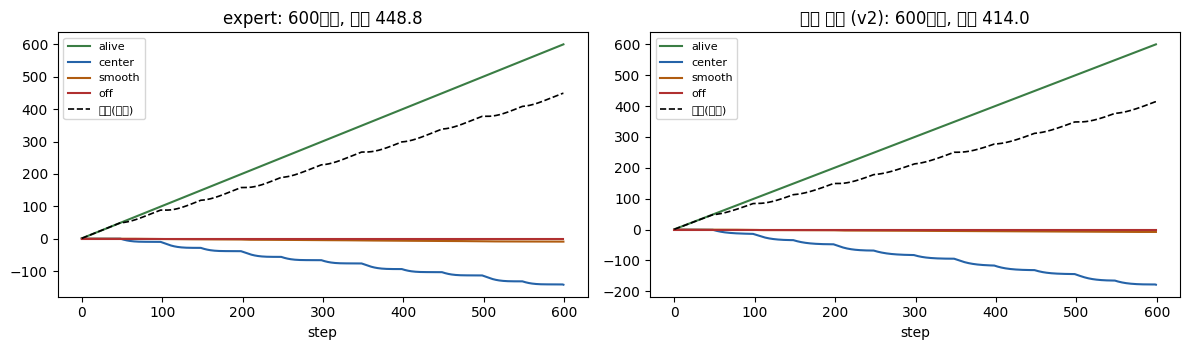

읽는 법: 리턴은 '살아 있음(+1)' 이 지배하고 수백 단위 → 그대로 두면 가치 함수가 수백을 맞춰야 함 (보상 0.1 배의 이유). 이탈은 −5 에 더해 남은 스텝의 +1 을 전부 잃는다.


In [3]:
def rollout_terms(pol, track="B", disturb=HARD, seed=0, max_steps=600):
    env = tt.Env(tt.Track.preset(track), disturb=disturb, seed=seed, max_steps=max_steps); obs = env.reset(seed=seed)
    rows = []
    for t in range(max_steps):
        a = pol(obs, env.state); obs, r, term, trunc, info = env.step(a)
        rows.append(dict(t=t, alive=1.0, center=-abs(info["d"]) / 0.5, smooth=-0.1 * abs(a), off=-5.0 * float(info["offtrack"]), r=r))
        if term or trunc: break
    return pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a_, (name, pol) in zip(ax, [("expert", tt.ExpertPolicy()), ("시작 정책 (v2)", pol_start)]):
    df = rollout_terms(pol)
    for col, c in [("alive", "#3A7D44"), ("center", "#2563A8"), ("smooth", "#B05C10"), ("off", "#B03030")]:
        a_.plot(df[col].cumsum(), color=c, label=col)
    a_.plot(df["r"].cumsum(), "k--", lw=1.2, label="합계(리턴)"); a_.set_title(f"{name}: {len(df)}스텝, 리턴 {df['r'].sum():.1f}"); a_.set_xlabel("step"); a_.legend(fontsize=8)
plt.tight_layout(); plt.savefig(SAVE_DIR / "reward_terms.png", dpi=120); plt.show()
print("읽는 법: 리턴은 '살아 있음(+1)' 이 지배하고 수백 단위 → 그대로 두면 가치 함수가 수백을 맞춰야 함 (보상 0.1 배의 이유). 이탈은 −5 에 더해 남은 스텝의 +1 을 전부 잃는다.")

## 2. 사전학습 정책 비교 — 무엇을 배웠는지가 표에 보인다
교수 GPU 에서 학습한 `ppo_scratch`(순수 PPO 40만 스텝)와 `ppo_bc12`(BC→RL, 외란 1.2× 학습)를 여러분의 시작 정책·`base_pilotnet_dr` 과 같은 표에 놓습니다. 레벨은 `tt.CHALLENGE_LEVELS` (L1 기본, L2 외란 1.2×/40, L4 속도 1.3×+외관).

In [4]:
pols = {"start (v2)": pol_start, "ppo_scratch": tt.OnnxPolicy(MODELS / "ppo_scratch.onnx"),
        "ppo_bc12": tt.OnnxPolicy(MODELS / "ppo_bc12.onnx"), "base_dr": tt.OnnxPolicy(MODELS / "base_pilotnet_dr.onnx")}
rows = []; t0 = time.time()
for name, pol in pols.items():
    row = dict(policy=name)
    for L in ("L1", "L2", "L4"):
        row[L] = round(tt.evaluate(pol, PUBLIC, seed=0, **tt.level_eval_kwargs(L, style_seed=7))["score"], 1)
    rows.append(row)
lv = pd.DataFrame(rows).set_index("policy"); print(lv.to_string(), f"\n({time.time()-t0:.0f}s, 트랙당 1 에피소드 — 교수 표는 2 에피소드 평균)")
print("\n교수 보고서 (공개):", {k: {L: v[L]["public"] for L in ("L1", "L2", "L4")} for k, v in REPORT.items() if k in ("ppo_scratch", "ppo_bc12", "base_pilotnet_dr")})
print("읽는 법: ppo_scratch 는 L1 최고, L2/L4 는 낮다(학습 세계만 안다). ppo_bc12 는 L4(속도) 에서 강하다. 둘 다 저조도·노이즈(L3)는 학습 데이터에 없어 약하다 — 11주차")

               L1    L2    L4
policy                       
start (v2)   86.7  17.3  57.8
ppo_scratch  90.5   9.6  44.4
ppo_bc12     88.3  23.3  72.0
base_dr      89.3  81.4  87.5 
(209s, 트랙당 1 에피소드 — 교수 표는 2 에피소드 평균)

교수 보고서 (공개): {'base_pilotnet_dr': {'L1': 88.9, 'L2': 82.1, 'L4': 88.0}, 'ppo_scratch': {'L1': 90.2, 'L2': 20.3, 'L4': 44.6}, 'ppo_bc12': {'L1': 87.8, 'L2': 32.1, 'L4': 65.1}}
읽는 법: ppo_scratch 는 L1 최고, L2/L4 는 낮다(학습 세계만 안다). ppo_bc12 는 L4(속도) 에서 강하다. 둘 다 저조도·노이즈(L3)는 학습 데이터에 없어 약하다 — 11주차


## 3. 단일 파일 PPO — 120줄
교수용 `ppo_tinytrack.py` 를 줄인 것. 구조: **벡터 환경**(8개) → **Agent**(actor = 시작 정책 그대로, critic = 별도 트렁크, log σ) → **롤아웃** → **GAE** → **클립 업데이트**(4에폭 × 4미니배치) + **critic 워밍업** + **BC 정규화**(시작 정책에 MSE 로 묶음).

In [5]:
def to_tensor(obs_batch):                                          # (N,66,200,3) uint8 → (N,3,66,200) float
    return torch.from_numpy(np.concatenate([tt.preprocess(o) for o in obs_batch]))

class VecTinyTrack:
    def __init__(self, n, tracks, disturb, seed=0, reset_spread=0.15):
        self.rng = np.random.RandomState(seed); self.spread = reset_spread
        self.envs = [tt.Env(tt.Track.preset(tracks[i % len(tracks)]), disturb=disturb, seed=seed + i, max_steps=1500) for i in range(n)]
        self.ep_ret = np.zeros(n); self.ep_len = np.zeros(n, int); self.finished = []       # (리턴, 진행/트랙길이)
    def _reset(self, i):
        e = self.envs[i]
        return e.reset(d0=float(np.clip(self.rng.normal(0, self.spread), -0.4, 0.4)), psi0=float(np.clip(self.rng.normal(0, self.spread), -0.5, 0.5)))
    def reset(self):
        return np.stack([self._reset(i) for i in range(len(self.envs))])
    def step(self, actions):
        obs, rews, dones = [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, info = e.step(float(a)); self.ep_ret[i] += r; self.ep_len[i] += 1
            if term or trunc:
                self.finished.append((self.ep_ret[i], info["progress"] / e.track.length)); self.ep_ret[i] = 0; self.ep_len[i] = 0; o = self._reset(i)
            obs.append(o); rews.append(r); dones.append(float(term))            # trunc 는 부트스트랩 유지(단순화: done 만)
        return np.stack(obs), np.array(rews, np.float32), np.array(dones, np.float32)

class Agent(nn.Module):
    def __init__(self, start_model, init_log_std=-1.5):
        super().__init__()
        self.actor = copy.deepcopy(start_model)                                # 시작 정책 (features + head)
        c = tt.make_model(); self.critic = nn.Sequential(c.features, nn.Flatten(), nn.Linear(64 * 18, 100), nn.ReLU(), nn.Linear(100, 1))
        self.log_std = nn.Parameter(torch.full((1,), float(init_log_std)))
    def dist(self, x):
        mean = self.actor(x).squeeze(-1); return torch.distributions.Normal(mean, self.log_std.exp().expand_as(mean)), mean
    def value(self, x):
        return self.critic(x).squeeze(-1)

class ActorPolicy:                                                              # 결정적 μ 로 폐루프 평가
    def __init__(self, actor): self.actor = actor
    def __call__(self, obs, state=None):
        with torch.no_grad(): return float(np.clip(self.actor(torch.from_numpy(tt.preprocess(obs))).item(), -1, 1))

def ppo_finetune(start_model, total_steps=16000, n_envs=8, T=64, lr_actor=1e-4, lr_critic=3e-4, gamma=0.99, lam=0.95, clip=0.2,
                 epochs=2, minibatches=2, reward_scale=0.1, critic_warmup=4, bc_coef=0.3, disturb=HARD, eval_every=4, eval_track="B", seed=0, log=None):
    torch.manual_seed(seed); np.random.seed(seed)
    venv = VecTinyTrack(n_envs, PUBLIC, disturb, seed=seed)
    agent = Agent(start_model); prior = copy.deepcopy(agent.actor).eval()
    for p in prior.parameters(): p.requires_grad_(False)
    actor_params = list(agent.actor.parameters()) + [agent.log_std]
    opt = torch.optim.Adam([dict(params=actor_params, lr=lr_actor), dict(params=agent.critic.parameters(), lr=lr_critic)], eps=1e-5)
    batch = n_envs * T; n_iters = max(1, total_steps // batch)
    obs_buf = torch.zeros((T, n_envs, 3, tt.H, tt.W)); act_buf = torch.zeros((T, n_envs)); logp_buf = torch.zeros((T, n_envs))
    rew_buf = torch.zeros((T, n_envs)); done_buf = torch.zeros((T, n_envs)); val_buf = torch.zeros((T, n_envs))
    next_obs = to_tensor(venv.reset()); next_done = torch.zeros(n_envs); log = [] if log is None else log
    best = (-1.0, None); t0 = time.time()
    for it in range(1, n_iters + 1):
        # ---- 롤아웃
        agent.eval()
        for t in range(T):
            with torch.no_grad():
                dist_, _ = agent.dist(next_obs); a = dist_.sample(); v = agent.value(next_obs)
            obs_buf[t], act_buf[t], logp_buf[t], val_buf[t], done_buf[t] = next_obs, a, dist_.log_prob(a), v, next_done
            o, r, dn = venv.step(a.numpy())
            rew_buf[t] = torch.from_numpy(r) * reward_scale; next_obs = to_tensor(o); next_done = torch.from_numpy(dn)
        # ---- GAE (뒤에서 앞으로)
        with torch.no_grad():
            next_v = agent.value(next_obs); adv = torch.zeros_like(rew_buf); last = torch.zeros(n_envs)
            for t in reversed(range(T)):
                nonterm = 1.0 - (next_done if t == T - 1 else done_buf[t + 1]); nv = next_v if t == T - 1 else val_buf[t + 1]
                delta = rew_buf[t] + gamma * nv * nonterm - val_buf[t]
                adv[t] = last = delta + gamma * lam * nonterm * last
            ret = adv + val_buf
        # ---- 업데이트
        agent.train()
        b_obs, b_act, b_logp, b_adv, b_ret, b_val = (x.reshape(-1, *x.shape[2:]) for x in (obs_buf, act_buf, logp_buf, adv, ret, val_buf))
        idx = np.arange(batch); mb = batch // minibatches; clipfracs = []
        for _ in range(epochs):
            np.random.shuffle(idx)
            for s in range(0, batch, mb):
                m = idx[s:s + mb]
                dist_, mean = agent.dist(b_obs[m]); newlogp = dist_.log_prob(b_act[m]); newv = agent.value(b_obs[m])
                ratio = (newlogp - b_logp[m]).exp(); madv = (b_adv[m] - b_adv[m].mean()) / (b_adv[m].std() + 1e-8)
                pg = torch.max(-madv * ratio, -madv * torch.clamp(ratio, 1 - clip, 1 + clip)).mean()
                v_clipped = b_val[m] + torch.clamp(newv - b_val[m], -clip, clip)
                vl = 0.5 * torch.max((newv - b_ret[m]) ** 2, (v_clipped - b_ret[m]) ** 2).mean()
                if it <= critic_warmup:
                    loss = 0.5 * vl                                              # 워밍업: critic 만
                else:
                    with torch.no_grad(): pm = prior(b_obs[m]).squeeze(-1)
                    loss = pg + 0.5 * vl + bc_coef * ((mean - pm) ** 2).mean()  # 클립 + 가치 + BC 정규화
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(agent.parameters(), 0.5); opt.step()
                clipfracs.append(((ratio - 1).abs() > clip).float().mean().item())
        # ---- 로그·평가
        fin = venv.finished[-20:]
        row = dict(iter=it, steps=it * batch, sec=round(time.time() - t0), warmup=it <= critic_warmup, std=round(agent.log_std.exp().item(), 3),
                   clipfrac=round(float(np.mean(clipfracs)), 3), ep_progress=round(float(np.mean([f[1] for f in fin])), 2) if fin else None)
        if it % eval_every == 0 or it == n_iters:
            agent.eval(); r = tt.evaluate(ActorPolicy(agent.actor), [eval_track], n_episodes=2, seed=0, disturb=disturb)
            row["score_hard"] = round(r["score"], 1)
            if r["score"] > best[0]: best = (r["score"], copy.deepcopy(agent.actor))
        log.append(row); print(row, flush=True)
    return best, log, agent
print("PPO 정의 완료")

PPO 정의 완료


## 4. BC→RL 미세조정 실행
시작 정책(v2)에서 외란 1.2× 환경으로 PPO (8 환경 × 64 스텝, 2 에폭 × 2 미니배치 — CPU 예산용 축약). 4 이터마다 트랙 B 에서 1.2× 폐루프 점수(결정적 μ, 2 에피소드)를 찍습니다. 1.6만 스텝은 교수 실험(6만 스텝)의 1/4 — **추세**를 보는 실습입니다. 기대: `score_hard` 가 오르는 추세, `std` 는 천천히 감소, `clipfrac` 0.05~0.2.

In [6]:
TOTAL_STEPS = 8000 if FAST else 16000
r0 = tt.evaluate(pol_start, ["B"], n_episodes=2, seed=0, disturb=HARD)["score"]; print(f"시작 정책 트랙 B 1.2× (2 에피소드): {r0:.1f}")
t0 = time.time()
(best_score, best_actor), log, agent = ppo_finetune(start, total_steps=TOTAL_STEPS)
print(f"\n{len(log)} 이터, {log[-1]['steps']} 스텝, 최고 트랙 B 1.2× score {best_score:.1f} (시작 {r0:.1f}), {time.time()-t0:.0f}s")
pd.DataFrame(log).to_csv(SAVE_DIR / "rl_log.csv", index=False)

시작 정책 트랙 B 1.2× (2 에피소드): 83.8
{'iter': 1, 'steps': 512, 'sec': 12, 'warmup': True, 'std': 0.223, 'clipfrac': 0.0, 'ep_progress': None}
{'iter': 2, 'steps': 1024, 'sec': 22, 'warmup': True, 'std': 0.223, 'clipfrac': 0.0, 'ep_progress': 0.22}
{'iter': 3, 'steps': 1536, 'sec': 34, 'warmup': True, 'std': 0.223, 'clipfrac': 0.0, 'ep_progress': 0.22}
{'iter': 4, 'steps': 2048, 'sec': 45, 'warmup': True, 'std': 0.223, 'clipfrac': 0.0, 'ep_progress': 0.29, 'score_hard': 83.8}
{'iter': 5, 'steps': 2560, 'sec': 77, 'warmup': False, 'std': 0.223, 'clipfrac': 0.029, 'ep_progress': 0.29}
{'iter': 6, 'steps': 3072, 'sec': 93, 'warmup': False, 'std': 0.223, 'clipfrac': 0.023, 'ep_progress': 0.3}
{'iter': 7, 'steps': 3584, 'sec': 110, 'warmup': False, 'std': 0.223, 'clipfrac': 0.009, 'ep_progress': 0.37}
{'iter': 8, 'steps': 4096, 'sec': 128, 'warmup': False, 'std': 0.223, 'clipfrac': 0.005, 'ep_progress': 0.43, 'score_hard': 11.3}
{'iter': 9, 'steps': 4608, 'sec': 146, 'warmup': False, 'std': 0.223,

## 5. 곡선 · 짝지은 비교 · 저장
곡선 하나로는 운(외란 시드)을 못 가립니다. 시작 정책과 최고 RL 정책을 **같은 시드 3개**로 짝지어 비교하고, 기본 외란(1.0×)에서 망각이 없는지도 확인합니다.

/tmp/ipykernel_1370/953816608.py:7: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png", dpi=120); plt.show()
/tmp/ipykernel_1370/953816608.py:7: UserWarning: Glyph 53597 (\N{HANGUL SYLLABLE TEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png", dpi=120); plt.show()
/tmp/ipykernel_1370/953816608.py:7: UserWarning: Glyph 52380 (\N{HANGUL SYLLABLE CEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png", dpi=120); plt.show()
/tmp/ipykernel_1370/953816608.py:7: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png", dpi=120); plt.show()
/tmp/ipykernel_1370/953816608.py:7: UserWarning: Glyph 47001 (\N{HANGUL SYLLABLE RAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png",

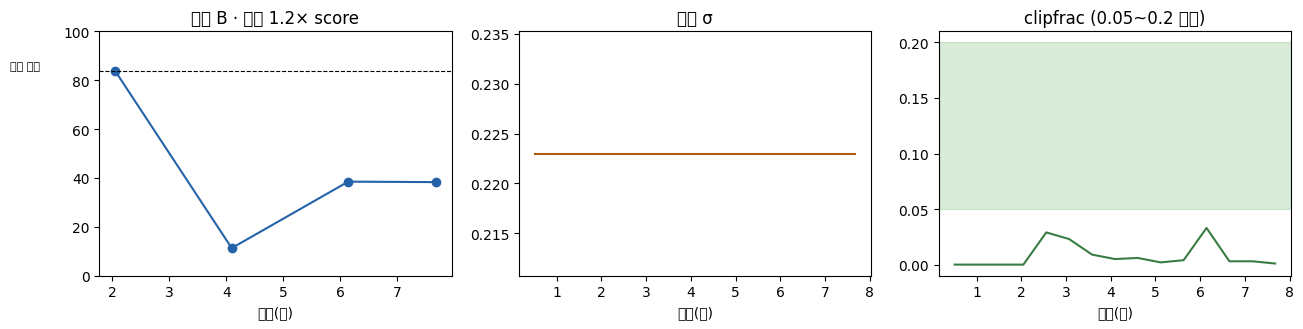

1.2× 외란  시작 [69.9 83.  55.9] → RL [69.9 83.  55.9] | 차이 평균 +0.0 (최소 +0.0)
1.0× 외란  시작 86.7 → RL 86.7  ← 망각 여부 (5점 이상 떨어지면 bc_coef ↑ 또는 actor lr ↓)  (161s)
저장: /content/drive/MyDrive/AIApp/week10/ppo_best.onnx | 리더보드에 제출 가능 (계약 동일)


In [7]:
df = pd.DataFrame(log); ev = df.dropna(subset=["score_hard"]) if "score_hard" in df else df.iloc[0:0]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(ev["steps"] / 1000, ev["score_hard"], "o-", color="#2563A8"); ax[0].axhline(r0, ls="--", c="k", lw=.8); ax[0].text(0.2, r0 + 1, "시작 정책", fontsize=8)
ax[0].set_title("트랙 B · 외란 1.2× score"); ax[0].set_xlabel("스텝(천)"); ax[0].set_ylim(0, 100)
ax[1].plot(df["steps"] / 1000, df["std"], color="#B05C10"); ax[1].set_title("정책 σ"); ax[1].set_xlabel("스텝(천)")
ax[2].plot(df["steps"] / 1000, df["clipfrac"], color="#3A7D44"); ax[2].axhspan(0.05, 0.2, alpha=.15, color="green"); ax[2].set_title("clipfrac (0.05~0.2 정상)"); ax[2].set_xlabel("스텝(천)")
plt.tight_layout(); plt.savefig(SAVE_DIR / "rl_curves.png", dpi=120); plt.show()

pol_rl = ActorPolicy(best_actor); seeds = (0, 1, 2); t0 = time.time()
a = np.array([tt.evaluate(pol_start, PUBLIC, seed=s, disturb=HARD)["score"] for s in seeds])
b = np.array([tt.evaluate(pol_rl, PUBLIC, seed=s, disturb=HARD)["score"] for s in seeds])
n0 = tt.evaluate(pol_start, PUBLIC, seed=0)["score"]; n1 = tt.evaluate(pol_rl, PUBLIC, seed=0)["score"]
print(f"1.2× 외란  시작 {a.round(1)} → RL {b.round(1)} | 차이 평균 {(b-a).mean():+.1f} (최소 {(b-a).min():+.1f})")
print(f"1.0× 외란  시작 {n0:.1f} → RL {n1:.1f}  ← 망각 여부 (5점 이상 떨어지면 bc_coef ↑ 또는 actor lr ↓)  ({time.time()-t0:.0f}s)")
onnx_path = tt.export_onnx(best_actor.cpu().eval(), SAVE_DIR / "ppo_best.onnx")
json.dump(dict(start_hard=a.tolist(), rl_hard=b.tolist(), start_normal=n0, rl_normal=n1, steps=int(df["steps"].iloc[-1]), best_track_B=best_score),
          open(SAVE_DIR / "rl_result.json", "w"), indent=1)
print("저장:", onnx_path.name if hasattr(onnx_path, "name") else onnx_path, "| 리더보드에 제출 가능 (계약 동일)")

## 6. (읽기) 보상 설계 — 가중치가 '누가 좋은 정책인가'를 바꾼다
학습 없이, 이미 있는 정책들을 **다른 보상 가중치**로 채점해 봅니다. 조향 페널티를 0.1 → 0.5 로 올리면 순위가 어떻게 바뀌나요? 보상 항의 크기가 곧 '의도'라는 것을 숫자로 확인합니다.

In [8]:
def score_under(pol, w_center=2.0, w_steer=0.1, w_off=5.0, track="B", seed=0, max_steps=600):
    env = tt.Env(tt.Track.preset(track), disturb=HARD, seed=seed, max_steps=max_steps); obs = env.reset(seed=seed); tot = 0.0
    for t in range(max_steps):
        a = pol(obs, env.state); obs, _, term, trunc, info = env.step(a)
        tot += 1.0 - w_center * abs(info["d"]) - w_steer * abs(a) - (w_off if info["offtrack"] else 0.0)
        if term or trunc: break
    return tot

class Jerky:                                              # 전문가 + 고주파 조향 노이즈 (부드럽지 않은 정책)
    def __init__(self): self.e, self.rng = tt.ExpertPolicy(), np.random.RandomState(0)
    def __call__(self, obs, state): return float(np.clip(self.e(obs, state) + self.rng.choice([-0.3, 0.3]), -1, 1))

cands = {"expert": tt.ExpertPolicy(), "jerky expert": Jerky(), "start (v2)": pol_start, "RL": pol_rl}
rows = []
for w_steer in (0.1, 0.5, 1.0):
    rows.append(dict(w_steer=w_steer, **{k: round(score_under(p, w_steer=w_steer), 1) for k, p in cands.items()}))
print(pd.DataFrame(rows).to_string(index=False))
print("읽는 법: 조향 가중치가 커질수록 '떨리는' 정책이 급격히 불리해진다 — 같은 주행, 다른 보상, 다른 순위. 보상은 무엇(완주·중앙)을 말하고 어떻게(부드러움)는 최소한으로.")

 w_steer  expert  jerky expert  start (v2)    RL
     0.1   448.8         425.7       414.0 414.0
     0.5   412.4         356.7       383.7 383.9
     1.0   367.0         237.8       345.8 346.2
읽는 법: 조향 가중치가 커질수록 '떨리는' 정책이 급격히 불리해진다 — 같은 주행, 다른 보상, 다른 순위. 보상은 무엇(완주·중앙)을 말하고 어떻게(부드러움)는 최소한으로.


## 정리 · 제출
- 보상은 라벨과 달리 '결과'를 말한다. 리턴의 크기(수백)를 0.1 배로 맞추고, actor/critic 트렁크를 분리하고, σ 를 작게 시작해야 BC 정책이 망가지지 않는다.
- PPO 는 정책 경사 + GAE + 클립. 단일 파일이면 무엇이 일어나는지 다 보인다.
- 순수 RL 은 학습 세계만 안다(ppo_scratch L2 20점). BC→RL 은 워밍업·작은 actor lr·BC 정규화로 망각 없이 다듬는다.

**리더보드**: `week10/ppo_best.onnx` 제출 가능. **과제 4** (`과제4_RL미니환경.ipynb`): 리턴·GAE·클립 손실·레벨 표·미세조정·보상 설계. 마감 11/10(화) 23:59.